# Proyecto 2 Resultados

**Pronóstico de TWS con Random Forest, XGBoost y LSTM**

Javier Valladares 23045, Ian Cumes 23236 y Javier Cifuentes 23079.

Este notebook reúne auditoría, protocolo, configuraciones y resultados de los experimentos ejecutados con `scripts/entrenar_modelos.py`. Por defecto inspecciona los artefactos guardados y verifica sus métricas. El entrenamiento completo se puede activar explícitamente en la sección correspondiente. Test.csv no contiene etiquetas y no se utiliza para atribuir una precisión conocida.

In [1]:
from pathlib import Path
import json, sys, subprocess
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if not (ROOT / 'config/modelado.json').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from tws.utils import RESULTS, FIGURES, FAMILIES, LABELS, sha256
AUDIT = json.loads((RESULTS / 'auditoria.json').read_text())
SUMMARY = json.loads((RESULTS / 'resumen_resultados.json').read_text())
pd.set_option('display.max_columns', 20)
print('Raíz del proyecto:', ROOT)
print('Familias:', ', '.join(LABELS[f] for f in FAMILIES))

Raíz del proyecto: /Users/javiervalladares/Library/Mobile Documents/com~apple~CloudDocs/Octavo Semestre/Datos/Proyecto2
Familias: Random Forest, XGBoost, LSTM


## 1 Datos originales y trazabilidad

Una fila representa una celda y un mes. Las etiquetas corresponden al siguiente mes calendario. Se conservaron los extremos y los archivos originales. Si están presentes los CSV crudos, se verifica su huella contra la ejecución registrada.

In [2]:
display(pd.DataFrame([{'conjunto':'Train','filas':AUDIT['train_rows'],'meses_observados':AUDIT['train_observed_months']},
                      {'conjunto':'Test','filas':AUDIT['test_rows'],'meses_observados':AUDIT['test_observed_months']}]))
print('Celdas:', AUDIT['cells'])
print('Meses calendario ausentes en Train:', len(AUDIT['train_missing_months']))
print('TWS oculto en Test:', f"{AUDIT['test_mask_rate']:.2%}")
for name, expected in AUDIT['raw_sha256'].items():
    path = ROOT / 'data/raw' / name
    if path.exists():
        assert sha256(path) == expected
        print(name, 'SHA-256 verificado')
    else:
        print(name, 'no incluido en la entrega; se conserva la huella de la ejecución original')
display(pd.read_csv(RESULTS / 'estadisticas_originales.csv', index_col=0))

,conjunto,filas,meses_observados
0,Train,2154021,138
1,Test,280961,18


Celdas: 15715
Meses calendario ausentes en Train: 22
TWS oculto en Test: 66.53%


Train.csv SHA-256 verificado


Test.csv SHA-256 verificado


,count,mean,std,min,1%,25%,50%,75%,99%,max
lat,2154021.0,33.082802,32.188686,-55.500000,-39.500000,9.500000,4.050000e+01,59.500000,80.500000,83.500000
lon,2154021.0,17.513523,85.319412,-179.500000,-154.500000,-63.500000,2.750000e+01,90.500000,165.500000,179.500000
TWS_t,2154021.0,0.116995,0.913025,-3.968328,-1.961138,-0.526700,1.315323e-01,0.785811,2.107384,4.057275
SPEI_01_t,2154021.0,-0.030368,0.956504,-4.247924,-1.970626,-0.748531,-5.587444e-02,0.666071,2.038867,3.475902
SPEI_03_t,2154021.0,-0.055324,0.944398,-5.225329,-1.985476,-0.761128,-7.610958e-02,0.631382,1.994847,4.177270
SPEI_06_t,2154021.0,-0.070566,0.939890,-4.383301,-2.003800,-0.769565,-8.940844e-02,0.609807,1.971220,4.850391
SPEI_12_t,2154021.0,-0.093270,0.930651,-4.622383,-2.009567,-0.779340,-1.134589e-01,0.574957,1.946387,3.764673
SOIL_MOISTURE_t,2154021.0,0.000779,0.787456,-5.107244,-2.106799,-0.445176,6.545279e-04,0.502670,1.930698,5.385165
month_sin,2154021.0,0.011193,0.704494,-1.000000,-1.000000,-0.500000,1.224647e-16,0.500000,1.000000,1.000000
month_cos,2154021.0,0.025502,0.709164,-1.000000,-1.000000,-0.500000,6.123234e-17,0.866025,1.000000,1.000000


## 2 Análisis exploratorio

El calendario contiene huecos y los ciclos regionales se compensan al promediar globalmente. La cobertura del hemisferio norte es mayor. Estos hallazgos motivan ventanas por mes calendario, estacionalidad y evaluación regional.

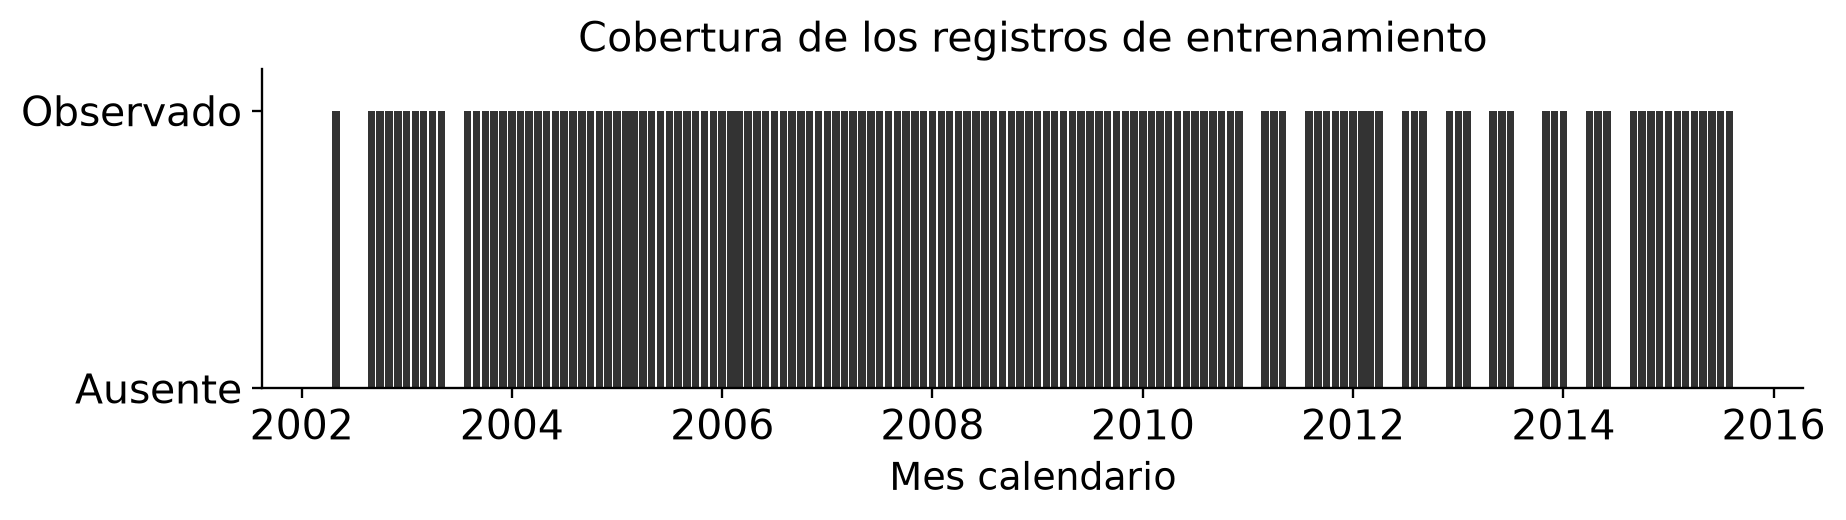

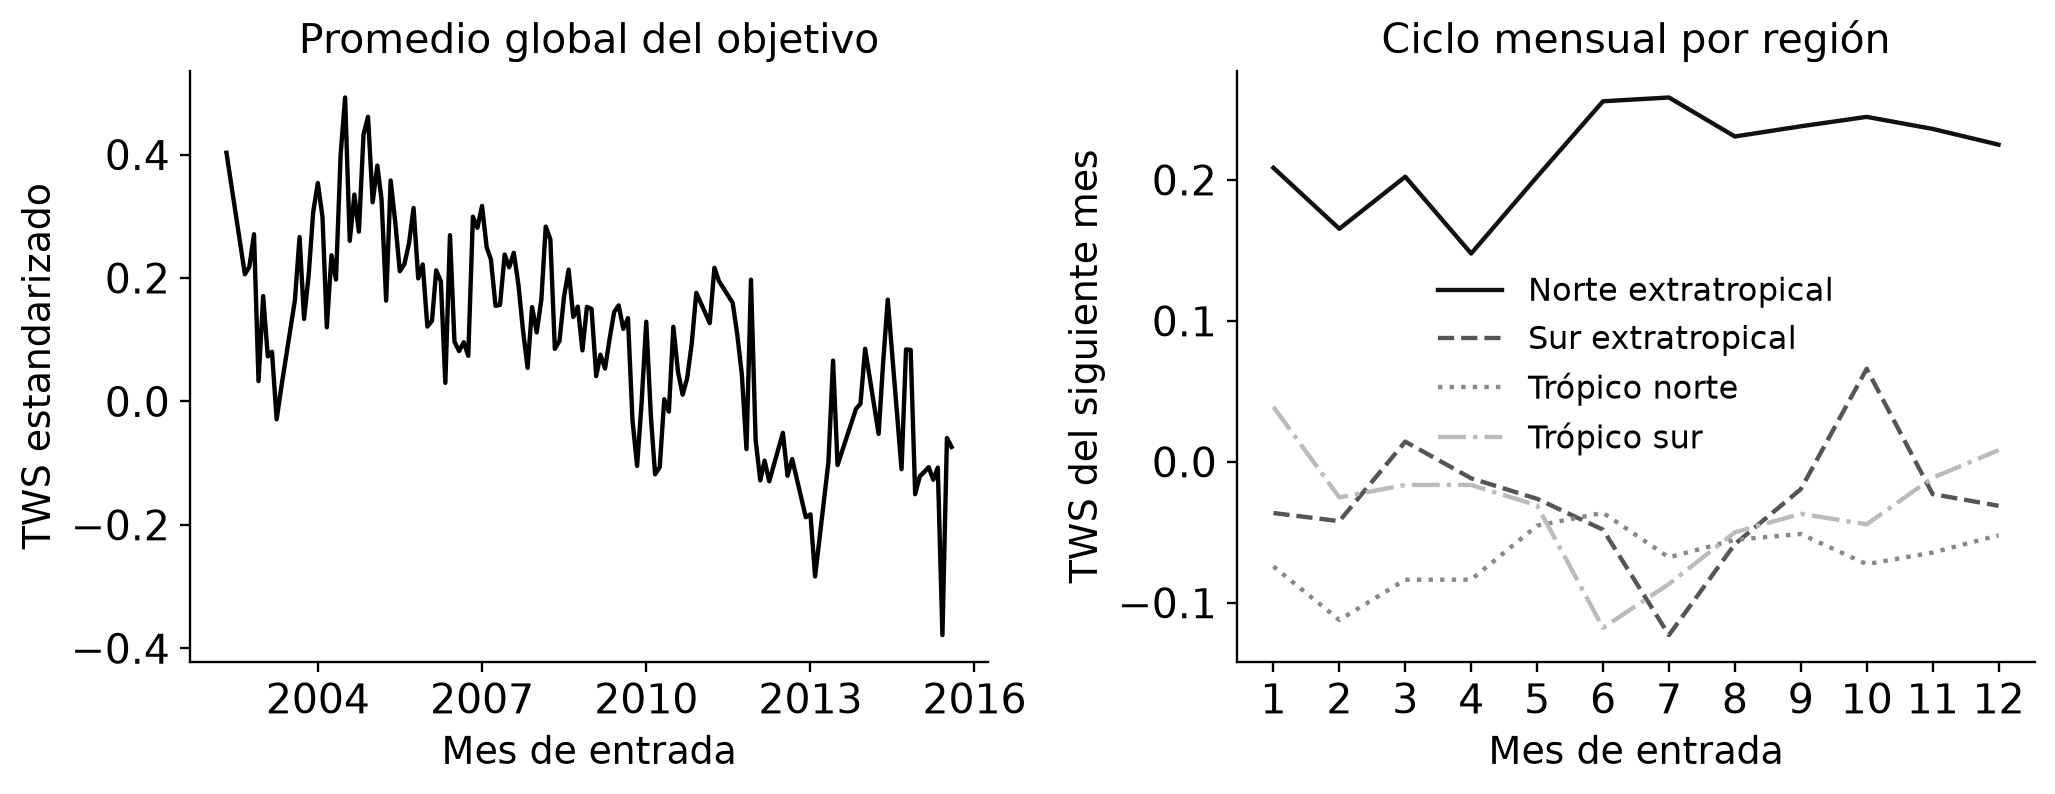

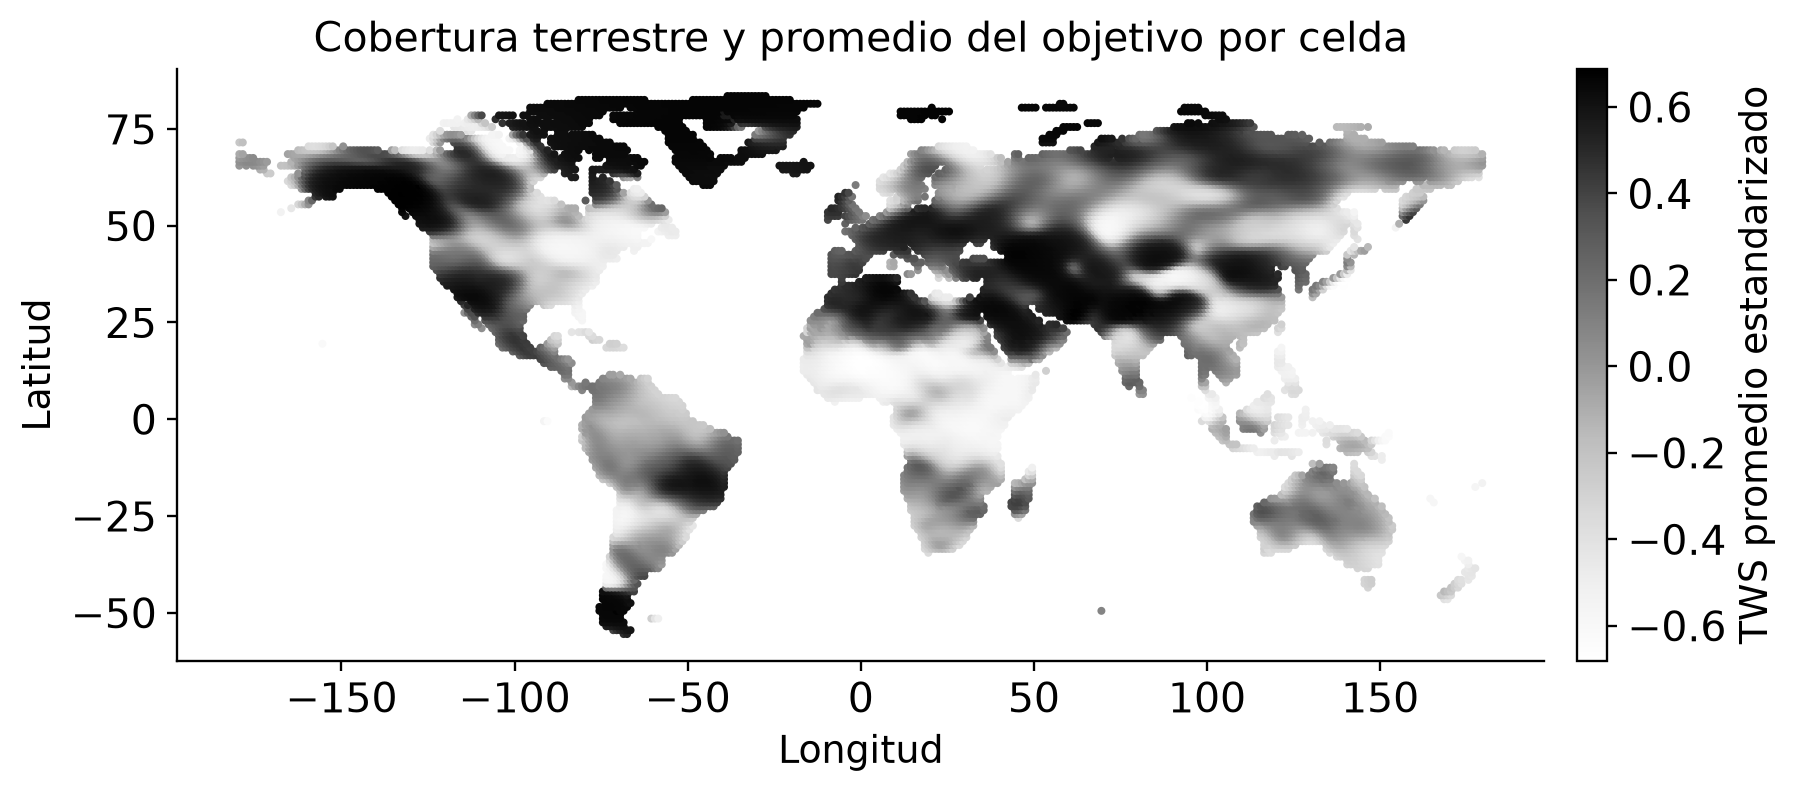

In [3]:
for name in ['00_cobertura_calendario.png','01_eda_temporal_estacional.png','02_eda_espacial.png']:
    display(Image(filename=str(FIGURES / name), width=950))

## 3 Protocolo temporal y prevención de fuga

Los cortes usan la fecha del objetivo. Las configuraciones se ajustan con 2011-2012, se confirman en 2013 y la prueba final de 2014-2015 queda fuera del ajuste. La historia solo utiliza TWS observable y covariables hasta la emisión. Los tres algoritmos reciben la misma información y la misma máscara.

In [4]:
display(pd.DataFrame(AUDIT['partitions']).T)
print('Máscara sintética global:', f"{AUDIT['synthetic_mask_rate']:.2%}")
print('Variables preparadas:', AUDIT['feature_count'])
from tws.data import feature_names
display(pd.DataFrame({'variable':feature_names()}))

,rows,target_start,target_end,masked_rate
ajuste_entrenamiento,1529620,2002-06-01,2010-12-01,0.671739
ajuste_validacion,249667,2011-01-01,2012-10-01,0.623174
confirmacion_entrenamiento,1779287,2002-06-01,2012-10-01,0.664925
confirmacion_validacion,109287,2013-01-01,2013-12-01,0.712464
prueba_entrenamiento,1888574,2002-06-01,2013-12-01,0.667676
prueba_reservada,265447,2014-01-01,2015-09-01,0.703971


Máscara sintética global: 67.21%
Variables preparadas: 57


,variable
0,SPEI_01_t_rezago_5
1,SPEI_03_t_rezago_5
2,SPEI_06_t_rezago_5
3,SPEI_12_t_rezago_5
4,SOIL_MOISTURE_t_rezago_5
5,TWS_observable_rezago_5
6,TWS_disponible_rezago_5
7,registro_disponible_rezago_5
8,SPEI_01_t_rezago_4
9,SPEI_03_t_rezago_4


## 4 Algoritmos y configuraciones

Random Forest representa una referencia tabular no lineal, XGBoost combina árboles de forma secuencial y LSTM aprende una representación de seis meses de historia. La revisión de literatura y las referencias APA se incluyen en el informe final. Las reglas del reto prohíben AutoML; las configuraciones se definieron manualmente.

In [5]:
CONFIG = json.loads((ROOT / 'config/modelado.json').read_text())
for family in FAMILIES:
    display(Markdown('### ' + LABELS[family]))
    display(pd.DataFrame(CONFIG[family]))

### Random Forest

,name,n_estimators,max_depth,min_samples_leaf,max_features,max_samples
0,RF_1,180,18,30,0.80,250000
1,RF_2,260,24,12,0.80,350000
2,RF_3,300,28,6,0.65,400000


### XGBoost

,name,max_depth,learning_rate,n_estimators,min_child_weight,subsample,colsample_bytree,reg_lambda
0,XGB_1,4,0.060,1400,30,0.85,0.85,10.0
1,XGB_2,6,0.040,1600,30,0.85,0.85,20.0
2,XGB_3,8,0.035,1800,60,0.85,0.85,30.0


### LSTM

,name,hidden_size,head_size,dropout,learning_rate,weight_decay,max_epochs,batch_size,patience
0,LSTM_1,32,32,0.10,0.0010,0.0001,35,2048,6
1,LSTM_2,64,32,0.15,0.0007,0.0002,40,2048,7
2,LSTM_3,64,64,0.25,0.0005,0.0010,45,2048,7


## 5 Ejecución o reanudación del entrenamiento

Los experimentos ya se ejecutaron y sus modelos están guardados. Active la siguiente variable para ejecutar el flujo y reutilizar sus checkpoints. El script aísla cada familia en un proceso para evitar conflictos de runtimes OpenMP en macOS. La selección se fija antes de la prueba reservada.

In [6]:
RUN_ENTRENAMIENTO = False
if RUN_ENTRENAMIENTO:
    subprocess.run([sys.executable, str(ROOT/'scripts/entrenar_modelos.py'), '--stage','all','--family','all'], cwd=ROOT, check=True)
else:
    print('Se documenta la ejecución real guardada; no se repite el entrenamiento.')
print(json.loads((RESULTS/'estado.json').read_text())['entrenamiento_completo']['status'])

Se documenta la ejecución real guardada; no se repite el entrenamiento.
complete


## 6 Resultados de ajuste y confirmación

La tabla reúne las nueve configuraciones evaluadas sobre las mismas filas. La confirmación de 2013 determina la familia recomendada. La prueba final no cambia retrospectivamente esta decisión.

,algorithm,family,configuration,n,rmse,mae,r2,bias,fit_seconds,peak_rss_mb,best_iterations,best_epochs,parameters
3,Random Forest,random_forest,RF_1,249667,0.566346,0.425594,0.609460,0.009267,251.716184,2082.656250,NaN,NaN,"{""n_estimators"": 180, ""max_depth"": 18, ""min_sa..."
4,Random Forest,random_forest,RF_2,249667,0.567987,0.426579,0.607194,0.004038,574.007771,1637.328125,NaN,NaN,"{""n_estimators"": 260, ""max_depth"": 24, ""min_sa..."
5,Random Forest,random_forest,RF_3,249667,0.566770,0.425526,0.608875,0.001865,708.592680,1610.484375,NaN,NaN,"{""n_estimators"": 300, ""max_depth"": 28, ""min_sa..."
2,XGBoost,xgboost,XGB_1,249667,0.548729,0.413377,0.633379,0.009442,21.429194,1829.250000,552.0,NaN,"{""max_depth"": 4, ""learning_rate"": 0.06, ""n_est..."
0,XGBoost,xgboost,XGB_2,249667,0.549189,0.411945,0.632765,-0.008470,19.749234,1560.031250,436.0,NaN,"{""max_depth"": 6, ""learning_rate"": 0.04, ""n_est..."
1,XGBoost,xgboost,XGB_3,249667,0.555302,0.417130,0.624544,0.002240,16.207606,1618.843750,230.0,NaN,"{""max_depth"": 8, ""learning_rate"": 0.035, ""n_es..."
6,LSTM,lstm,LSTM_1,249667,0.568285,0.431543,0.606782,-0.014394,67.470059,2262.015625,NaN,1.0,"{""hidden_size"": 32, ""head_size"": 32, ""dropout""..."
7,LSTM,lstm,LSTM_2,249667,0.562127,0.424592,0.615258,-0.027178,101.837707,2178.812500,NaN,1.0,"{""hidden_size"": 64, ""head_size"": 32, ""dropout""..."
8,LSTM,lstm,LSTM_3,249667,0.561028,0.423915,0.616760,0.015187,103.038224,1567.546875,NaN,1.0,"{""hidden_size"": 64, ""head_size"": 64, ""dropout""..."


,stage,family,algorithm,n,rmse,mae,r2,bias,fit_seconds,predict_seconds,inference_ms_per_1000,peak_rss_mb,model_size_mb,configuration
0,confirmation,random_forest,Random Forest,109287,0.543009,0.409594,0.462543,0.041171,243.480871,0.197028,3.163450,1848.015625,43.018070,RF_1
1,confirmation,xgboost,XGBoost,109287,0.542357,0.409568,0.463833,0.028789,14.332069,0.059263,0.571833,2305.515625,0.901158,XGB_1
2,confirmation,lstm,LSTM,109287,0.549613,0.417981,0.449391,0.033779,14.663376,0.251292,2.574633,1934.875000,0.094396,LSTM_3


Recomendación fijada: XGBoost


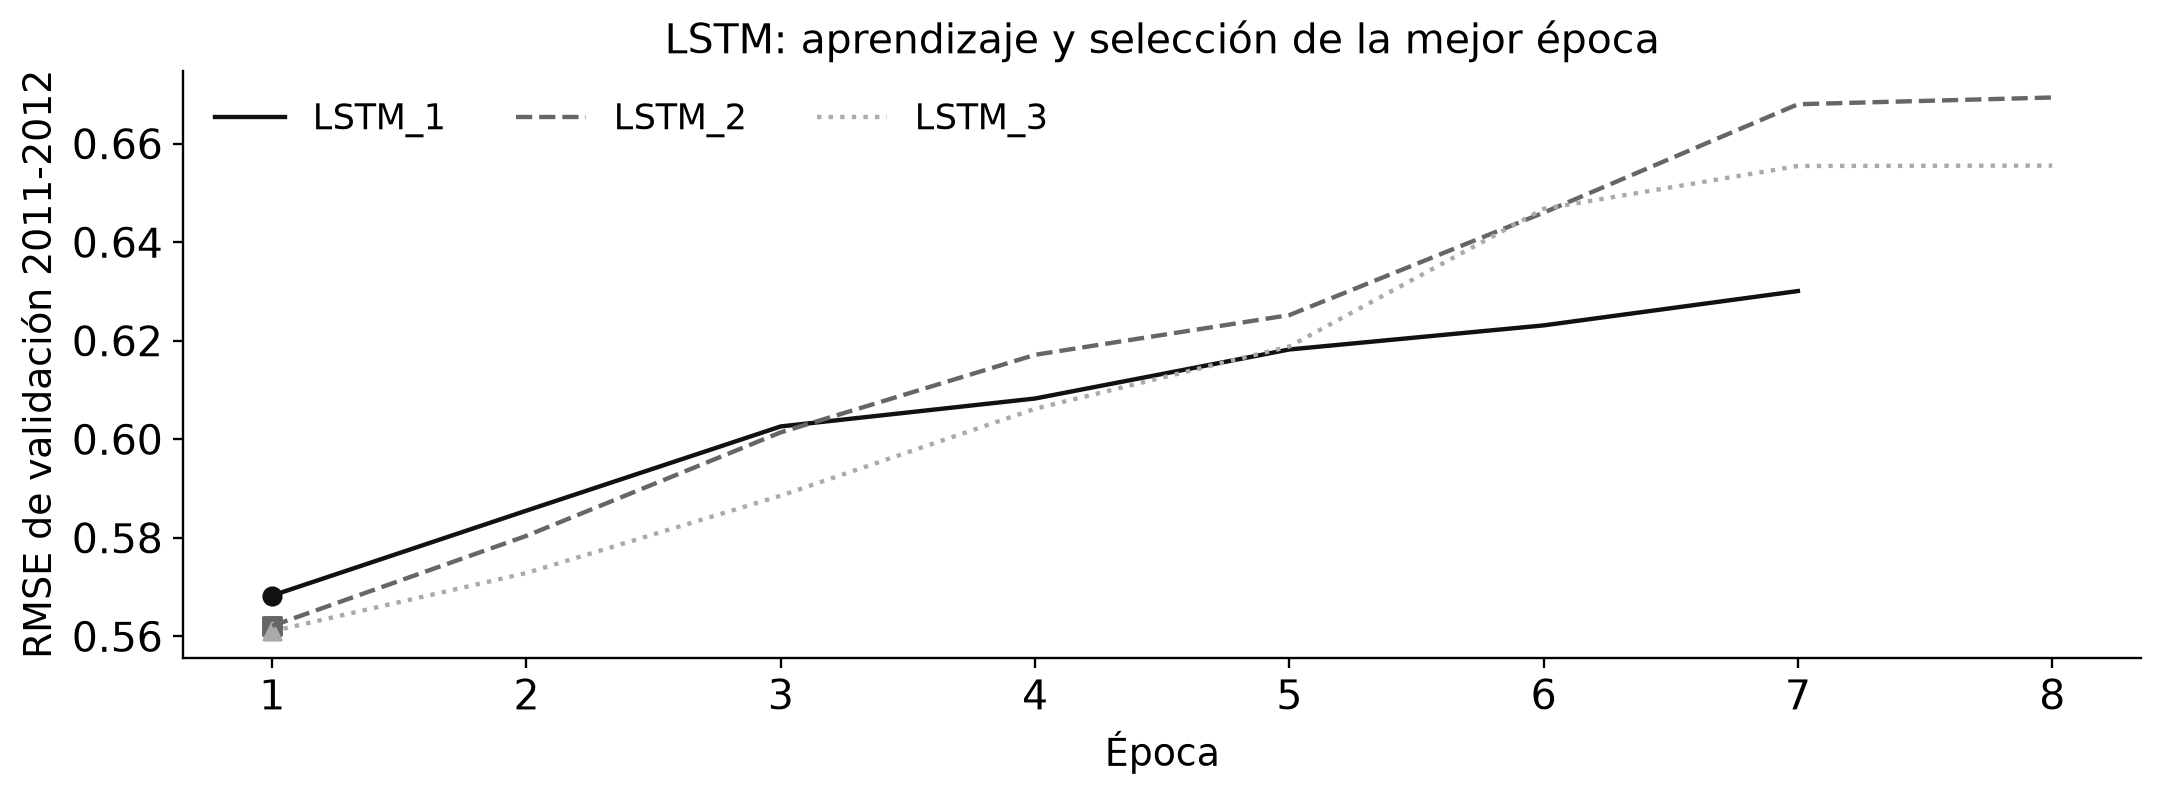

In [7]:
experiments = pd.read_csv(RESULTS/'experimentos.csv')
experiments['orden'] = experiments.family.map({f:i for i,f in enumerate(FAMILIES)})
display(experiments.sort_values(['orden','configuration']).drop(columns='orden'))
performance = pd.read_csv(RESULTS/'metricas_modelos.csv')
display(performance[performance.stage=='confirmation'])
print('Recomendación fijada:', LABELS[SUMMARY['recommended_family']])
display(Image(filename=str(FIGURES/'11_aprendizaje_lstm.png'), width=950))

## 7 Prueba final reservada y comprobación de métricas

Se recalcula el RMSE desde las predicciones individuales. Todos los modelos se evalúan con las mismas observaciones; se distingue el resultado final del ajuste de parámetros y de las predicciones no etiquetadas de Test.

,stage,family,algorithm,n,rmse,mae,r2,bias,fit_seconds,predict_seconds,inference_ms_per_1000,peak_rss_mb,model_size_mb,configuration
3,holdout,random_forest,Random Forest,265447,0.716151,0.529016,0.283697,0.031184,247.183068,0.497028,3.076488,2329.328125,43.454305,RF_1
4,holdout,xgboost,XGBoost,265447,0.703481,0.520752,0.308818,0.023923,23.574744,0.281882,1.132508,2401.531250,0.900445,XGB_1
5,holdout,lstm,LSTM,265447,0.698856,0.518603,0.317875,0.032589,18.333872,0.671982,2.755092,2221.656250,0.094396,LSTM_3


,stage,algorithm,n,rmse,mae,r2,bias
0,tuning,Persistencia causal,249667,0.642050,0.468740,0.498074,-0.007394
1,tuning,Climatología mensual,249667,1.069589,0.863787,-0.392948,0.138748
2,confirmation,Persistencia causal,109287,0.663967,0.489558,0.196432,-0.028097
3,confirmation,Climatología mensual,109287,1.002134,0.833269,-0.830548,0.284771
4,holdout,Persistencia causal,265447,0.848603,0.610594,-0.005766,0.043388
5,holdout,Climatología mensual,265447,1.114880,0.934866,-0.735978,0.193447


Random Forest RMSE verificado: 0.716151
XGBoost RMSE verificado: 0.703481
LSTM RMSE verificado: 0.698856


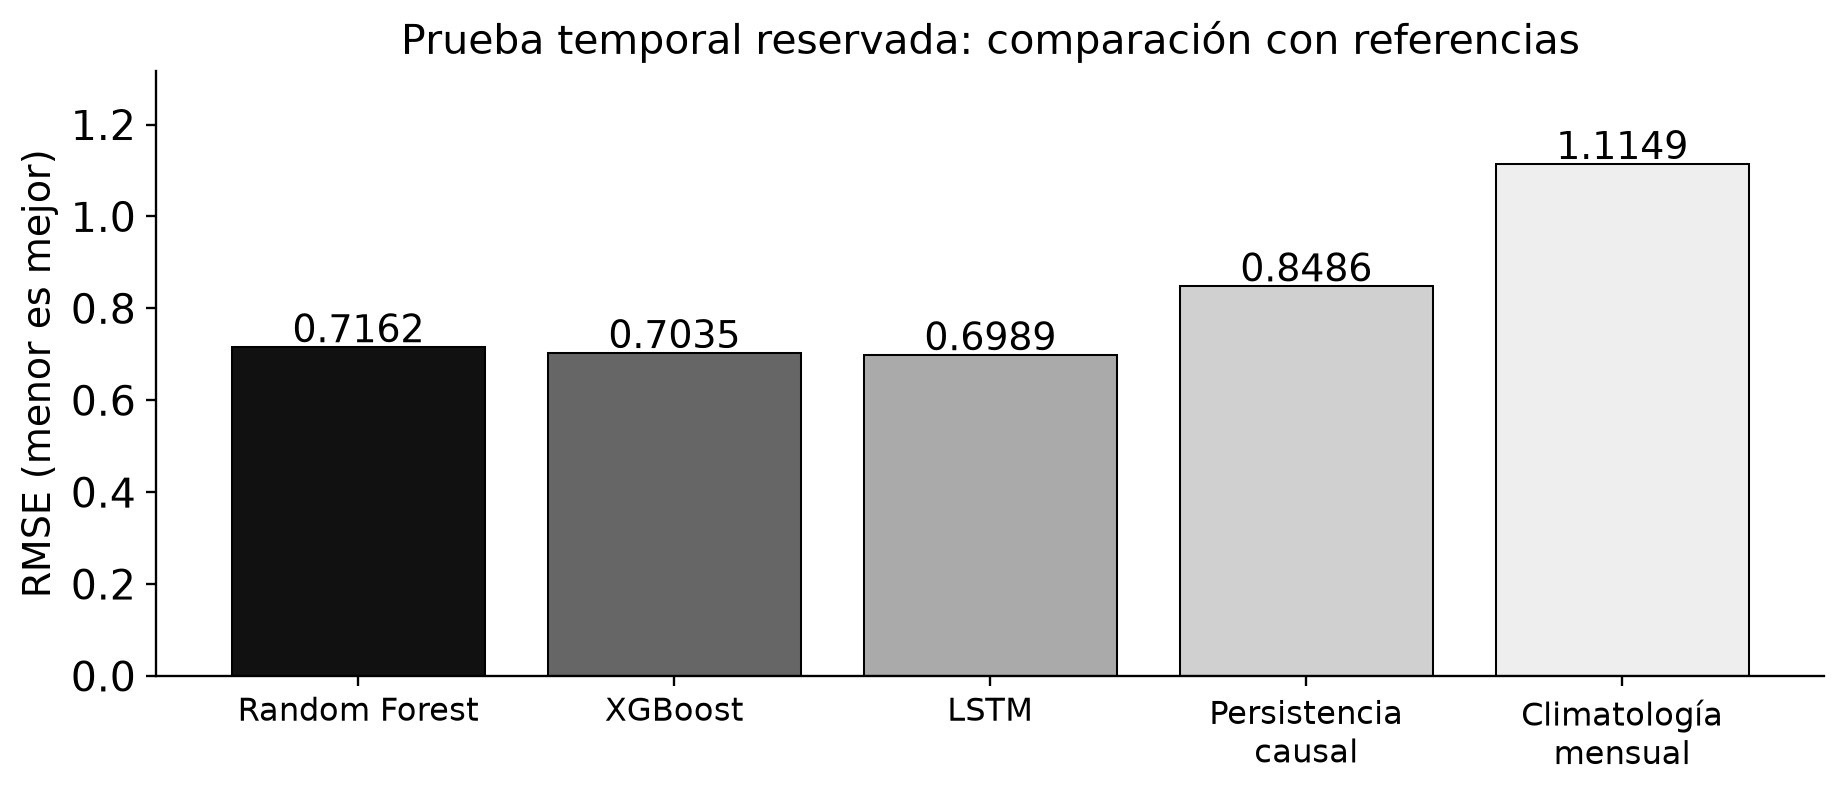

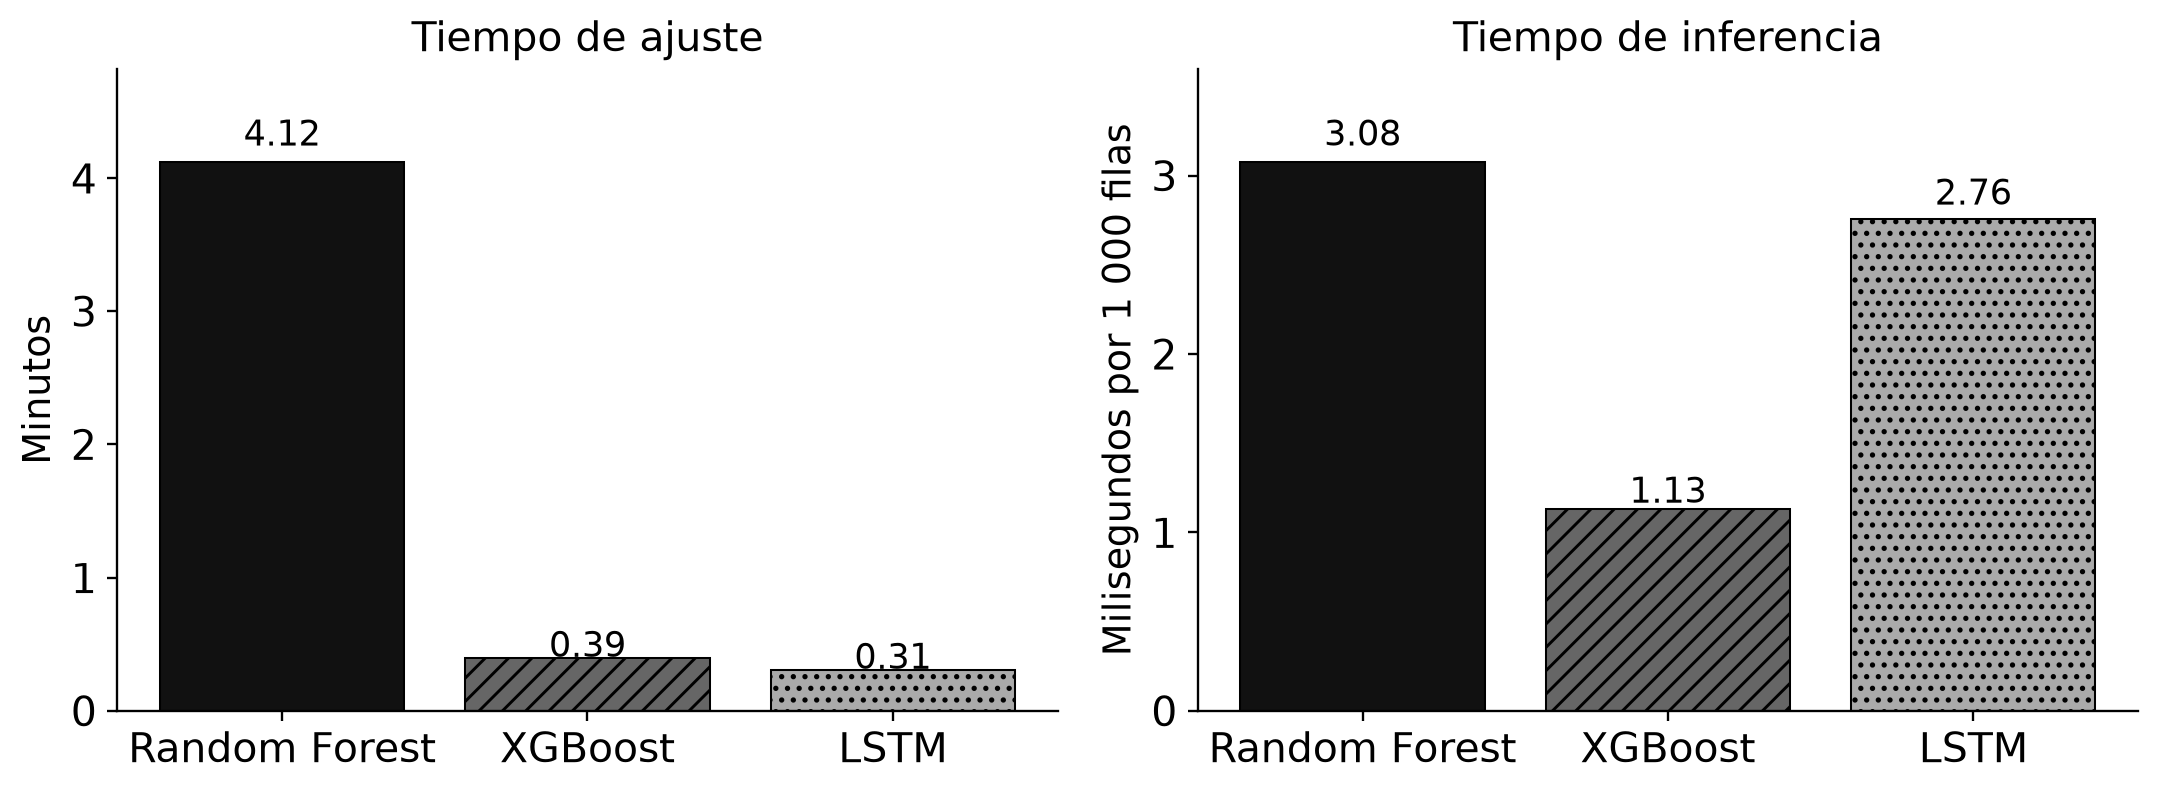

In [8]:
display(performance[performance.stage=='holdout'])
display(pd.read_csv(RESULTS/'metricas_referencias.csv'))
predictions = pd.read_parquet(RESULTS/'predicciones_prueba_completas.parquet')
for family in FAMILIES:
    error = predictions[f'pred_{family}'].to_numpy(dtype=float) - predictions.target.to_numpy(dtype=float)
    recalculated = np.sqrt(np.mean(error**2))
    recorded = performance.loc[(performance.stage=='holdout') & (performance.family==family),'rmse'].iloc[0]
    assert abs(recalculated-recorded)<1e-9
    print(LABELS[family], 'RMSE verificado:', round(recalculated,6))
display(Image(filename=str(FIGURES/'03_comparacion_rmse.png'), width=950))
display(Image(filename=str(FIGURES/'04_eficiencia.png'), width=950))

## 8 Tiempo, regiones, disponibilidad y extremos

Una mejora global debe interpretarse junto con los grupos donde el error aumenta. Las diferencias entre grupos son asociaciones predictivas; no aíslan un efecto causal del enmascaramiento.

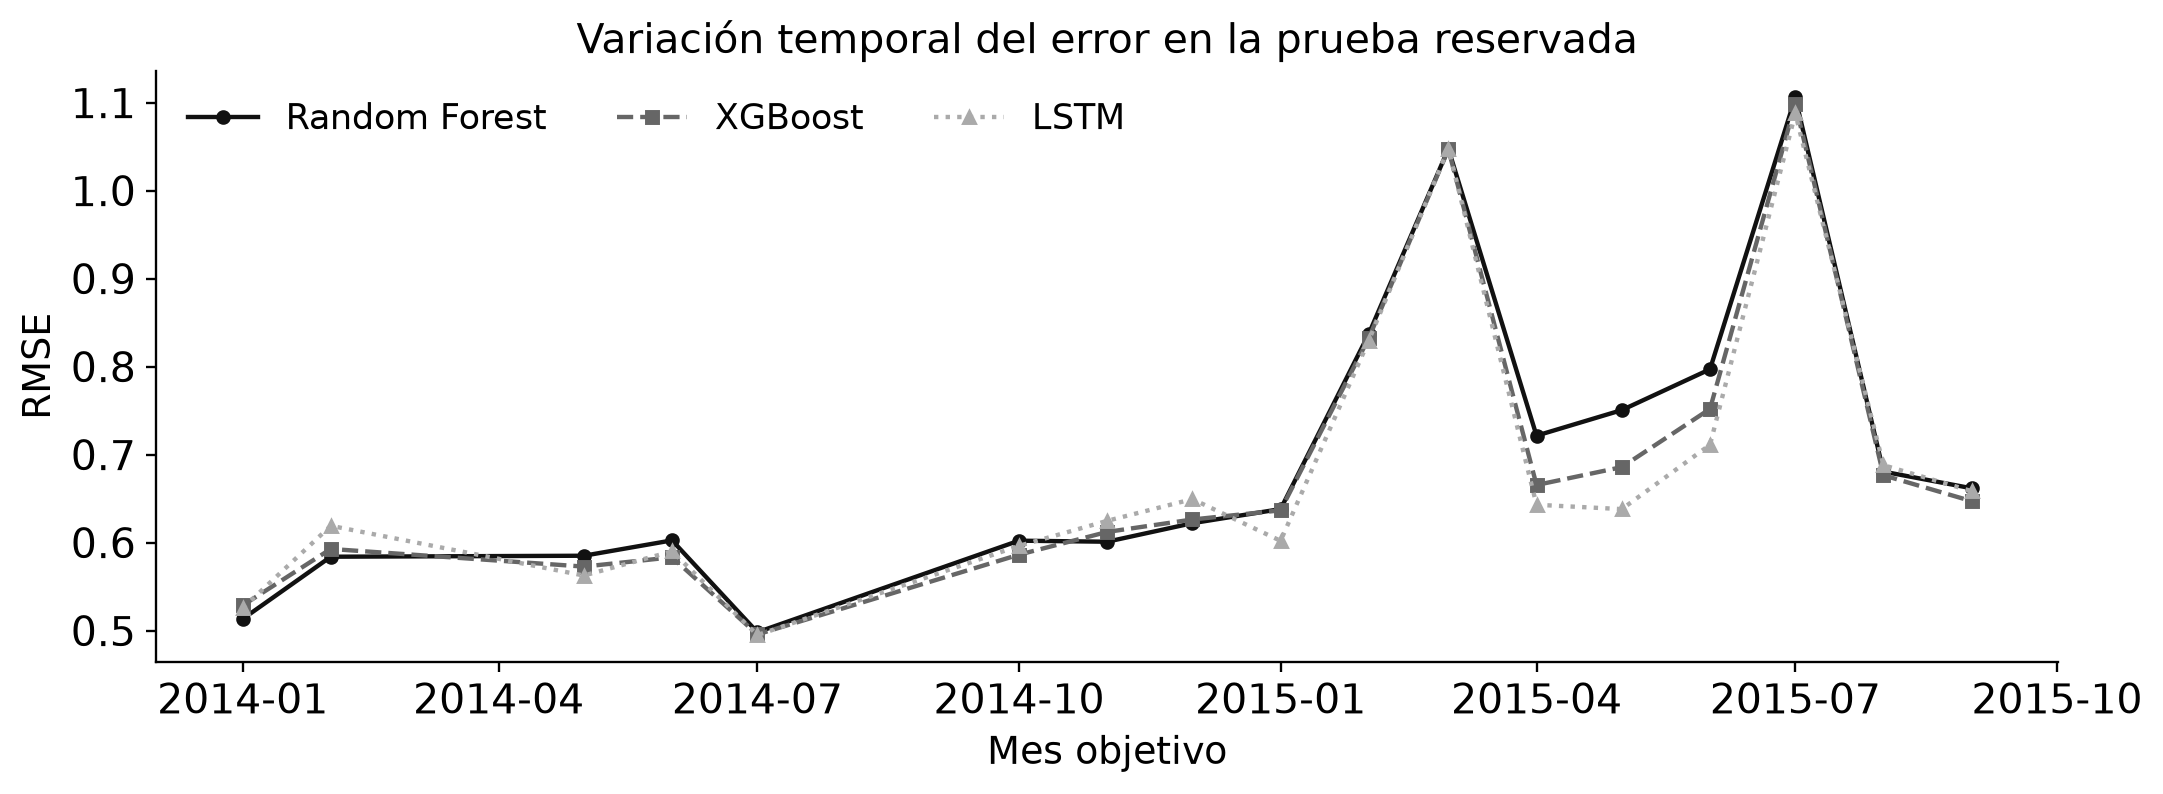

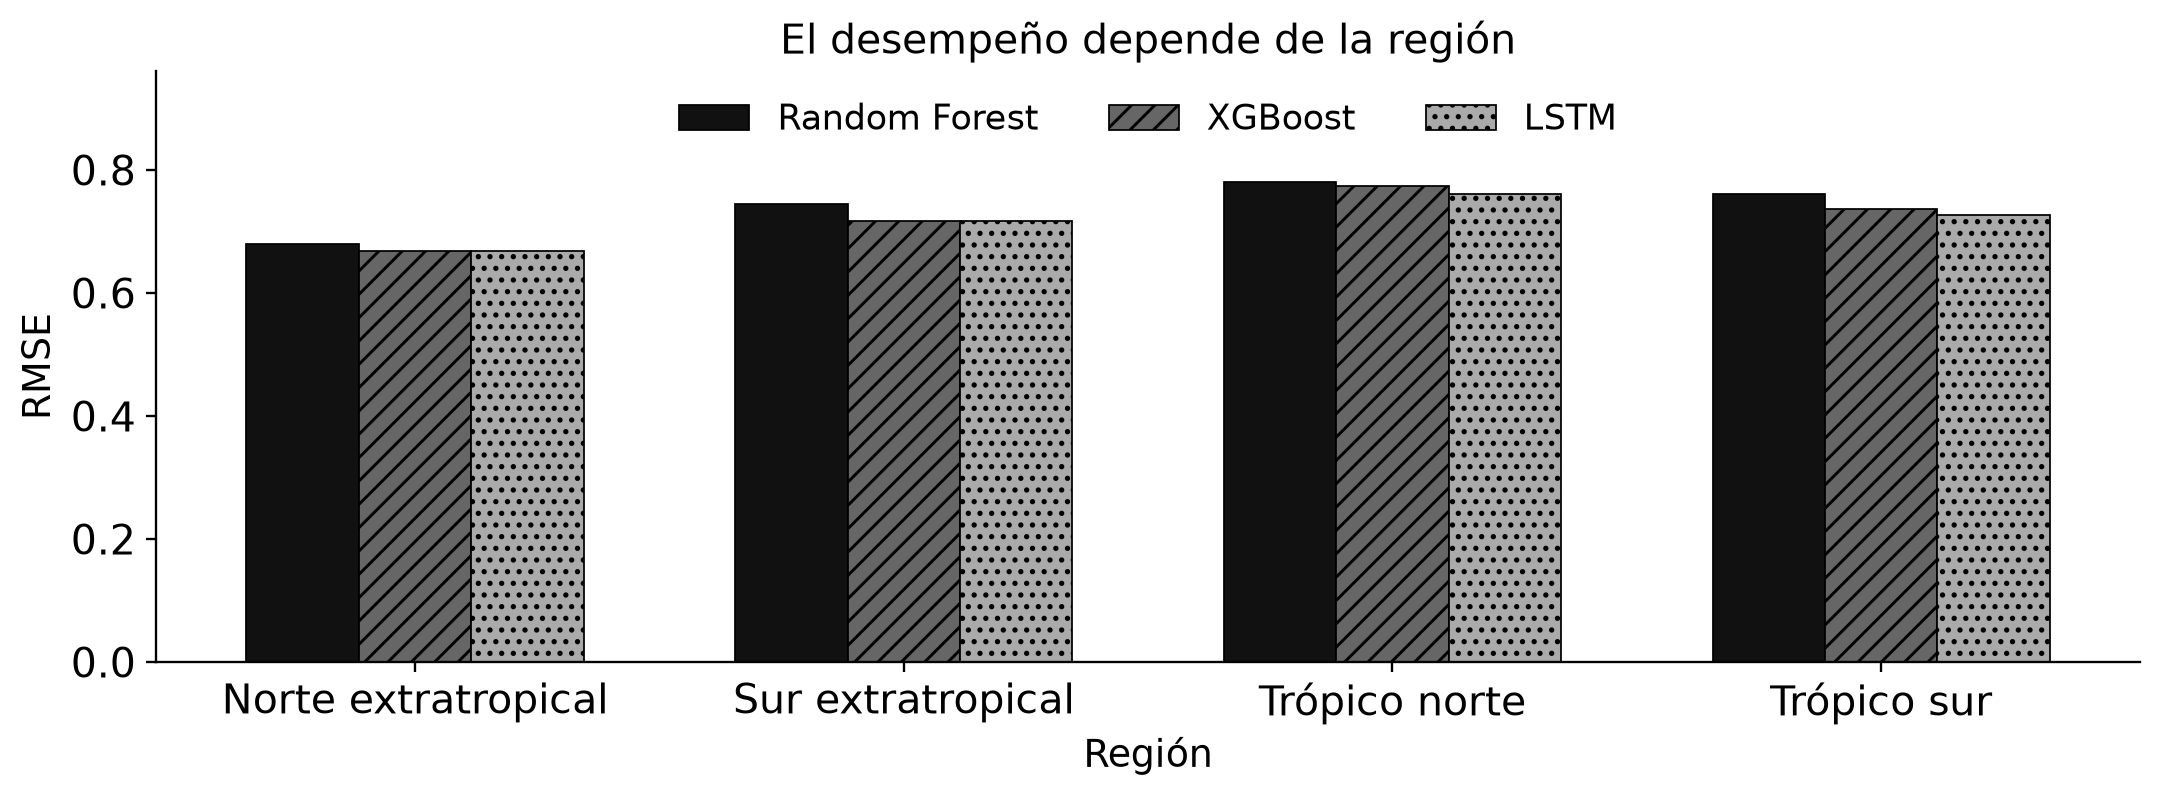

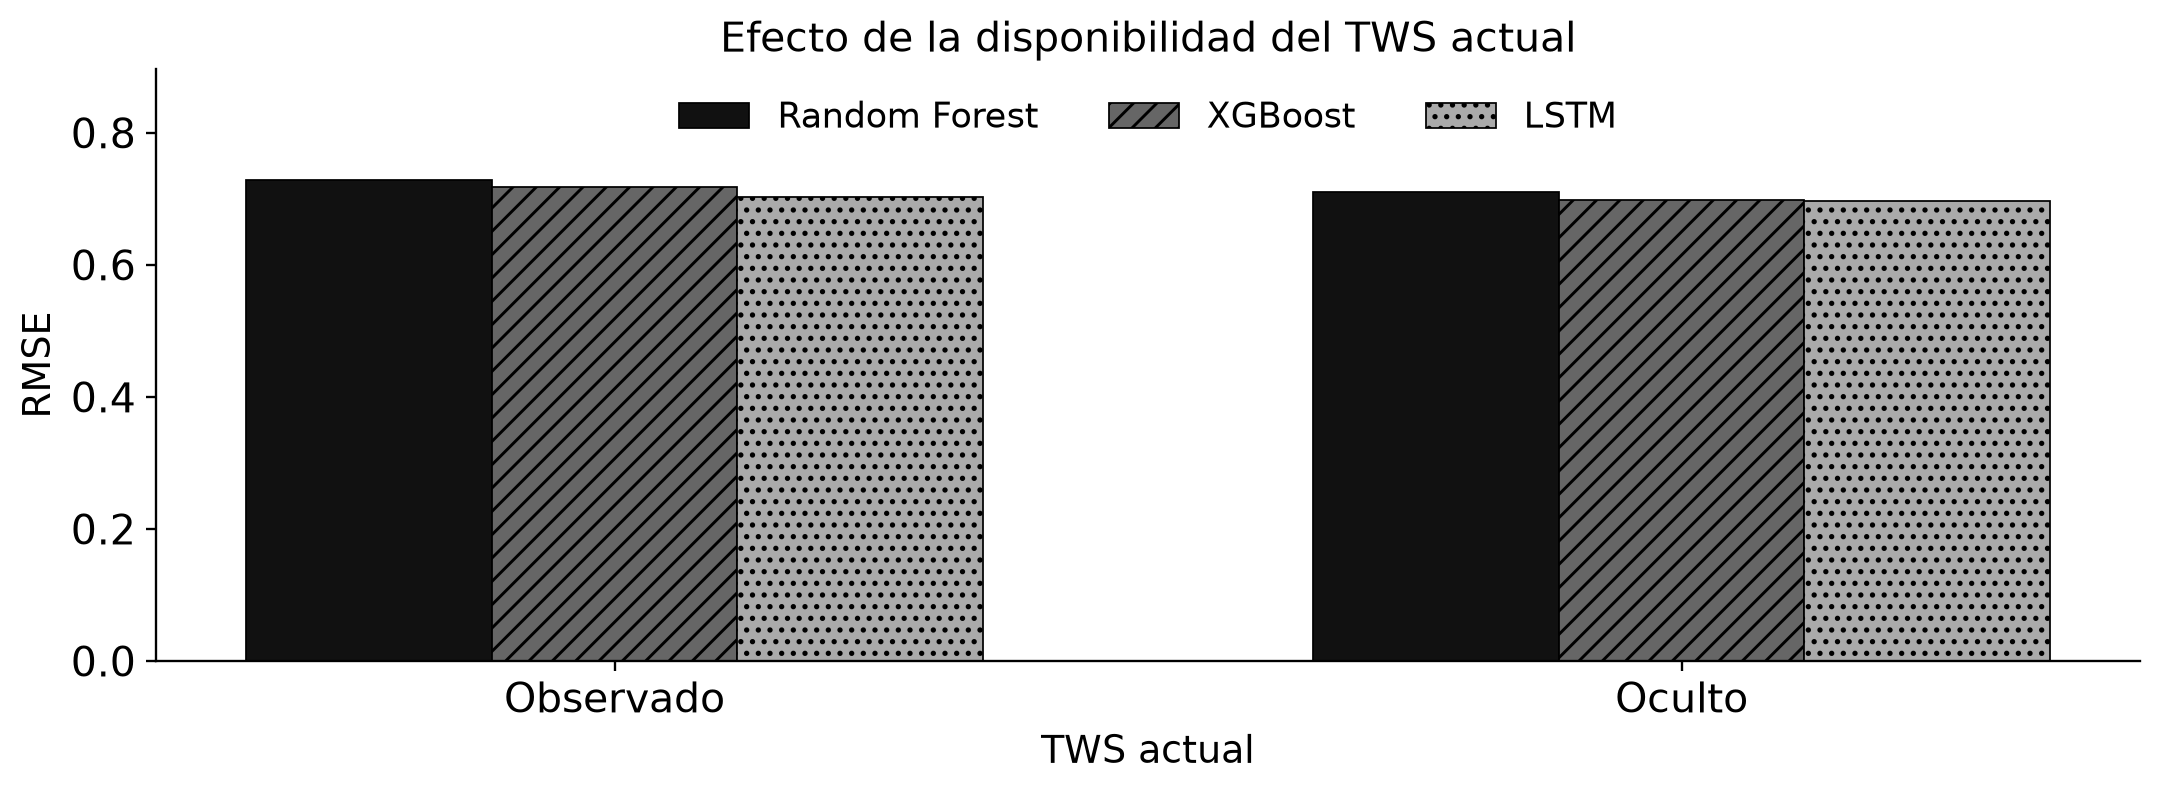

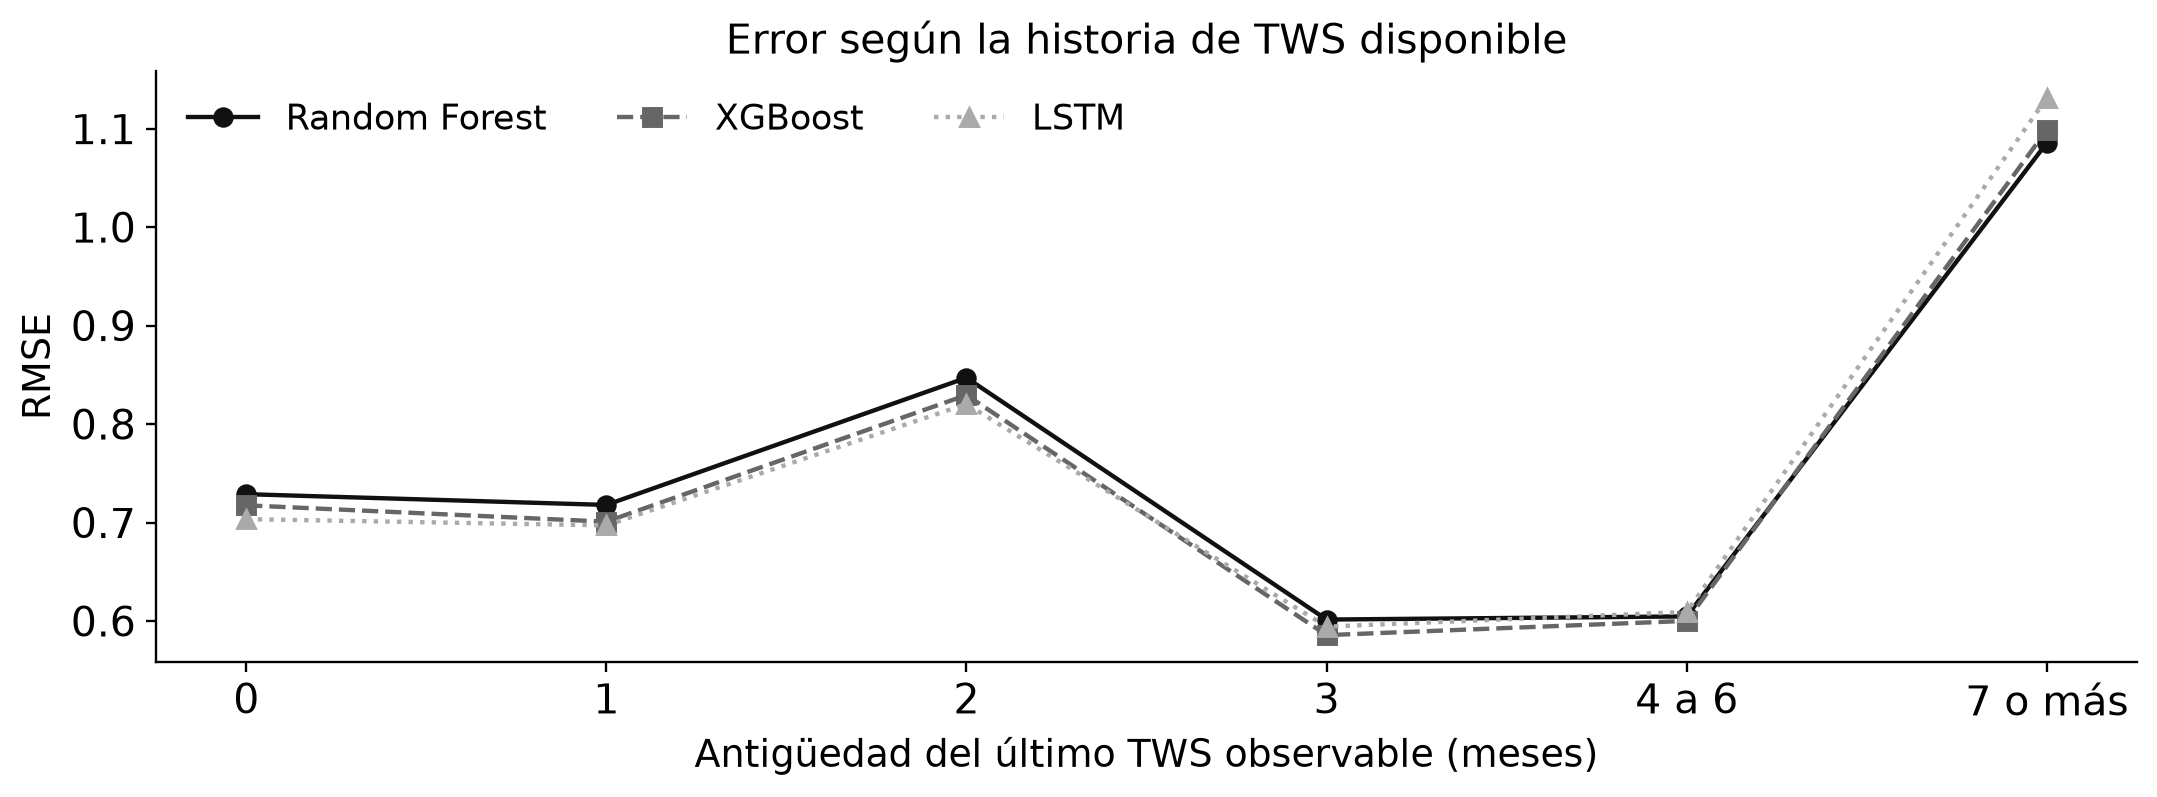

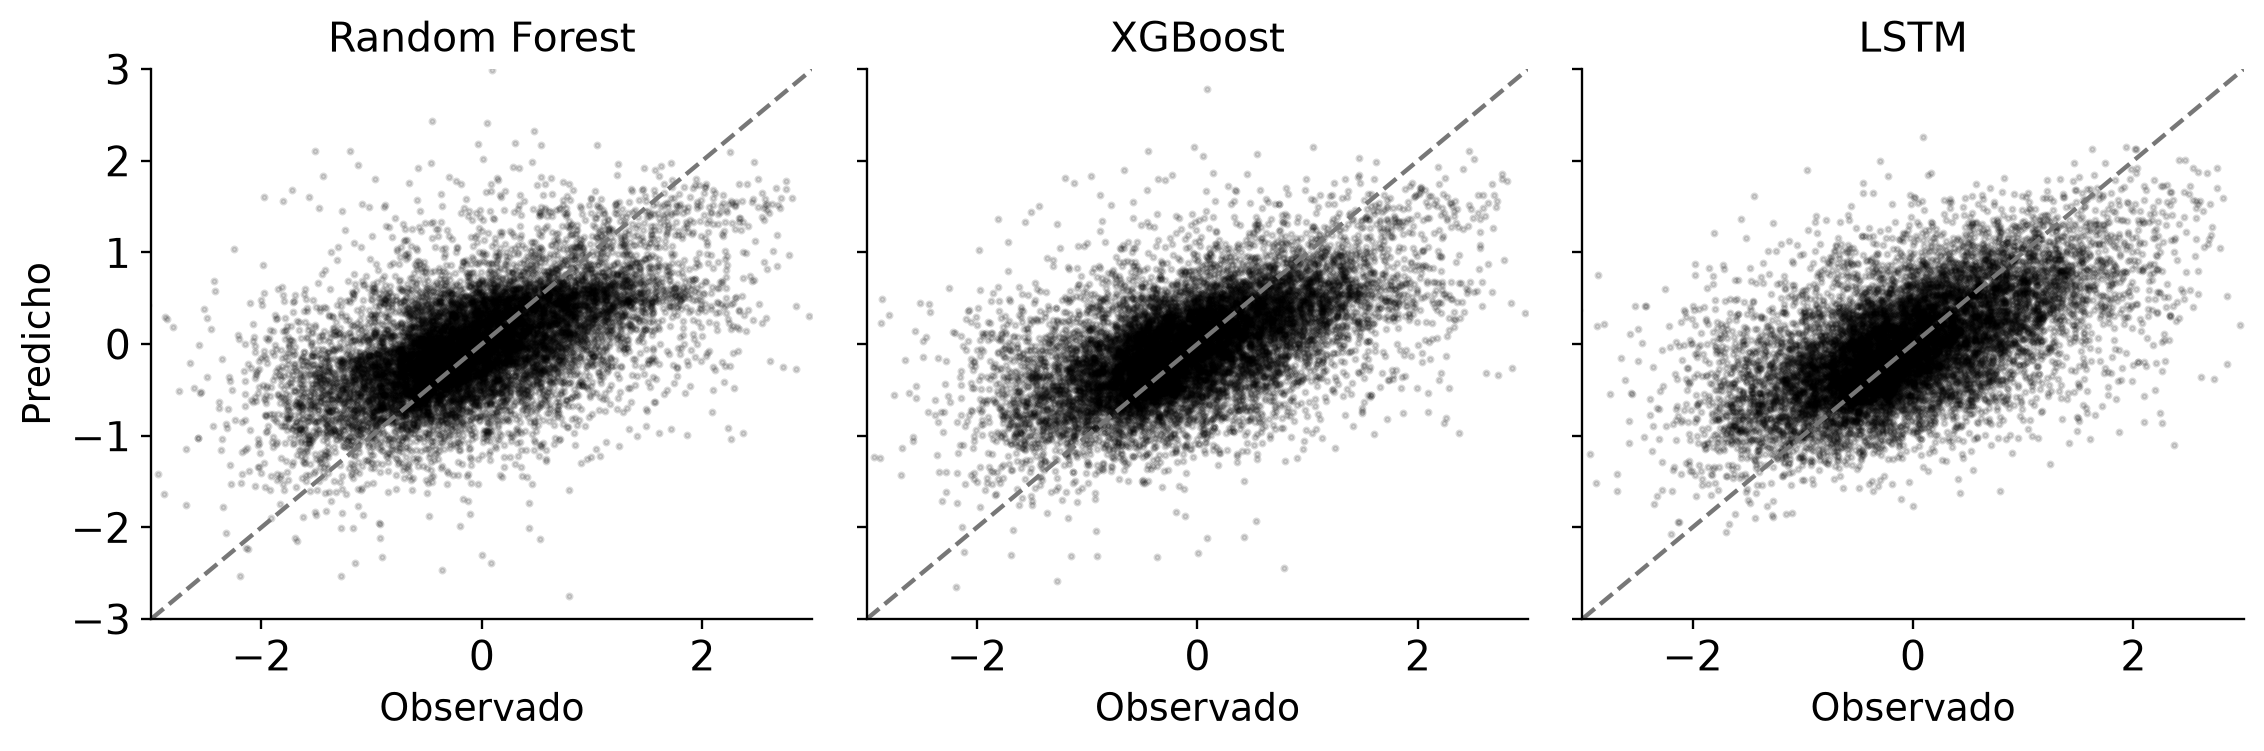

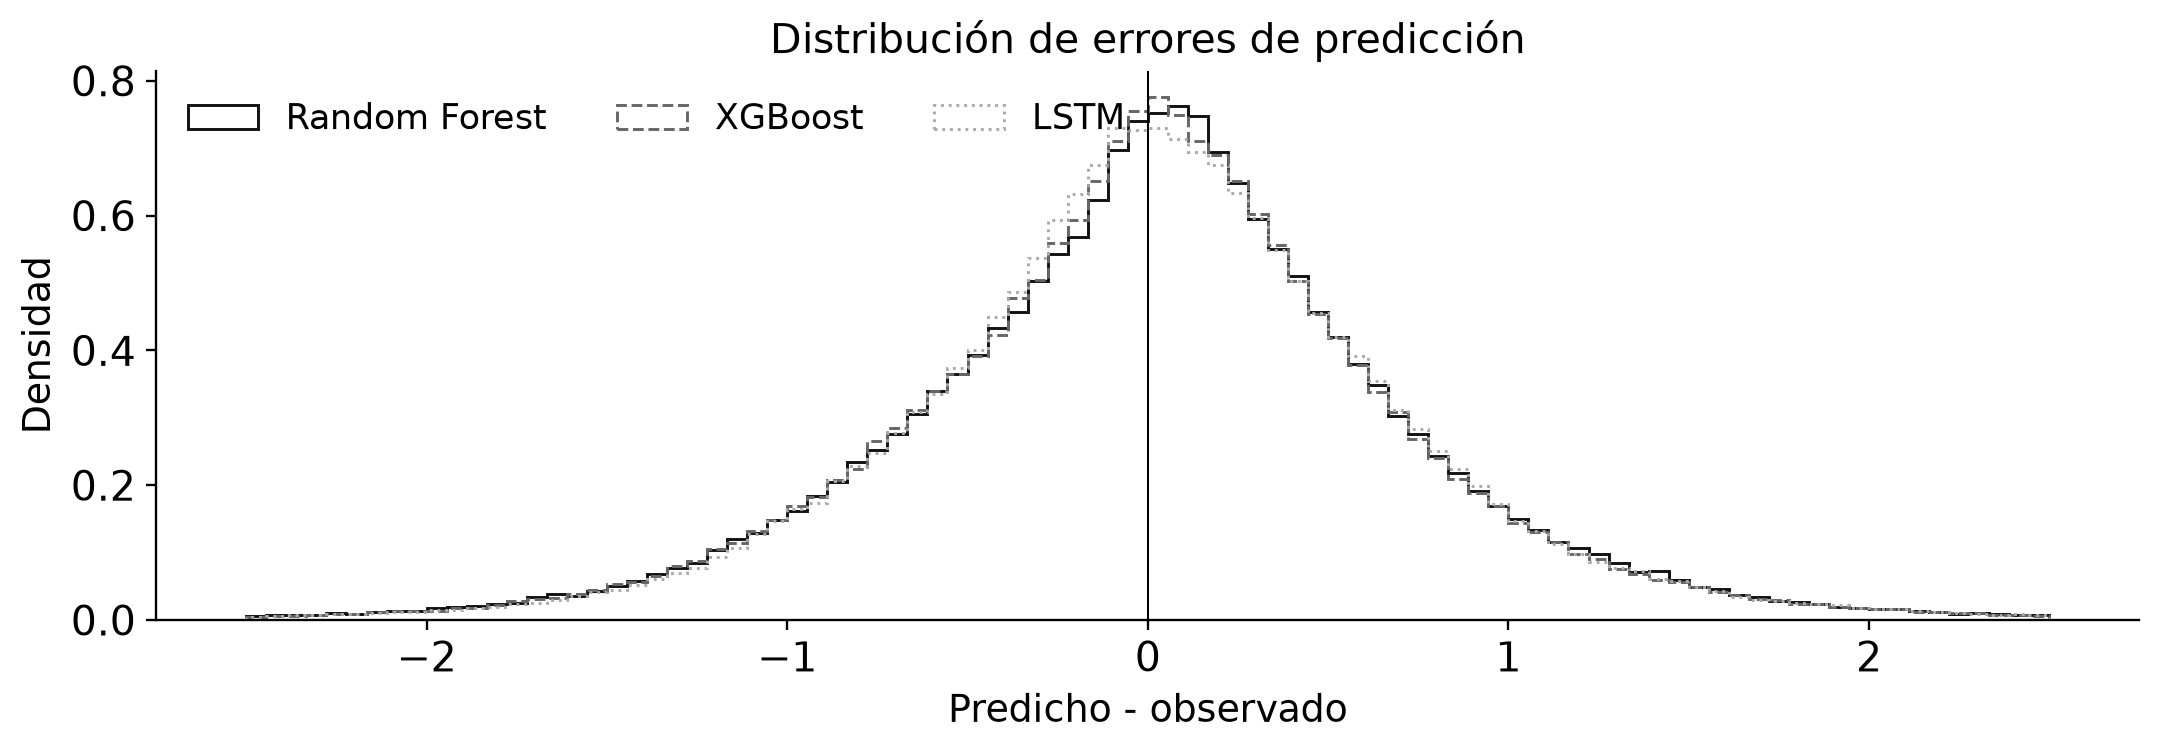

,extreme_group,algorithm,family,n,rmse,mae,r2,bias
0,Bajo percentil 10,Random Forest,random_forest,25849,1.212419,1.025506,-9.473700,1.003858
1,Bajo percentil 10,XGBoost,xgboost,25849,1.205885,1.021551,-9.361113,1.004501
2,Bajo percentil 10,LSTM,lstm,25849,1.189939,0.998911,-9.088912,0.985971
3,Intervalo central,Random Forest,random_forest,222661,0.565808,0.429442,0.031771,0.001692
4,Intervalo central,XGBoost,xgboost,222661,0.549656,0.419838,0.086261,-0.006634
5,Intervalo central,LSTM,lstm,222661,0.552268,0.423949,0.077556,0.001678
6,Sobre percentil 90,Random Forest,random_forest,16937,1.259337,1.080330,-9.355120,-1.065583
7,Sobre percentil 90,XGBoost,xgboost,16937,1.251002,1.083104,-9.218495,-1.070913
8,Sobre percentil 90,LSTM,lstm,16937,1.218127,1.029932,-8.688489,-1.016075


Cortes de extremos fijados en entrenamiento: {'p10': -1.0909910321235656, 'p90': 1.2966929793357849}


In [9]:
for name in ['05_error_temporal.png','06_error_regional.png','07_error_disponibilidad.png','08_error_antiguedad.png','09_observado_predicho.png','10_residuos.png']:
    display(Image(filename=str(FIGURES/name), width=950))
display(pd.read_csv(RESULTS/'metricas_extremos.csv'))
print('Cortes de extremos fijados en entrenamiento:', SUMMARY['extreme_thresholds_training'])

## 9 Incertidumbre e interpretación

El remuestreo circular usa bloques de tres meses observados y mantiene juntas las celdas del mismo mes. Un intervalo de diferencia que incluye cero no respalda un orden temporal estable. Las importancias de árboles se agrupan por dominio y no prueban causalidad.

Meses observados: 17 Remuestreos: 2000


,family,algorithm,rmse_low,rmse_high
0,random_forest,Random Forest,0.601554,0.823704
1,xgboost,XGBoost,0.597397,0.802975
2,lstm,LSTM,0.601416,0.793200


,first,second,difference_rmse,ci_low,ci_high,includes_zero
0,random_forest,xgboost,0.012670,0.001168,0.026543,False
1,random_forest,lstm,0.017294,-0.003718,0.042841,True
2,xgboost,lstm,0.004625,-0.006046,0.016256,True


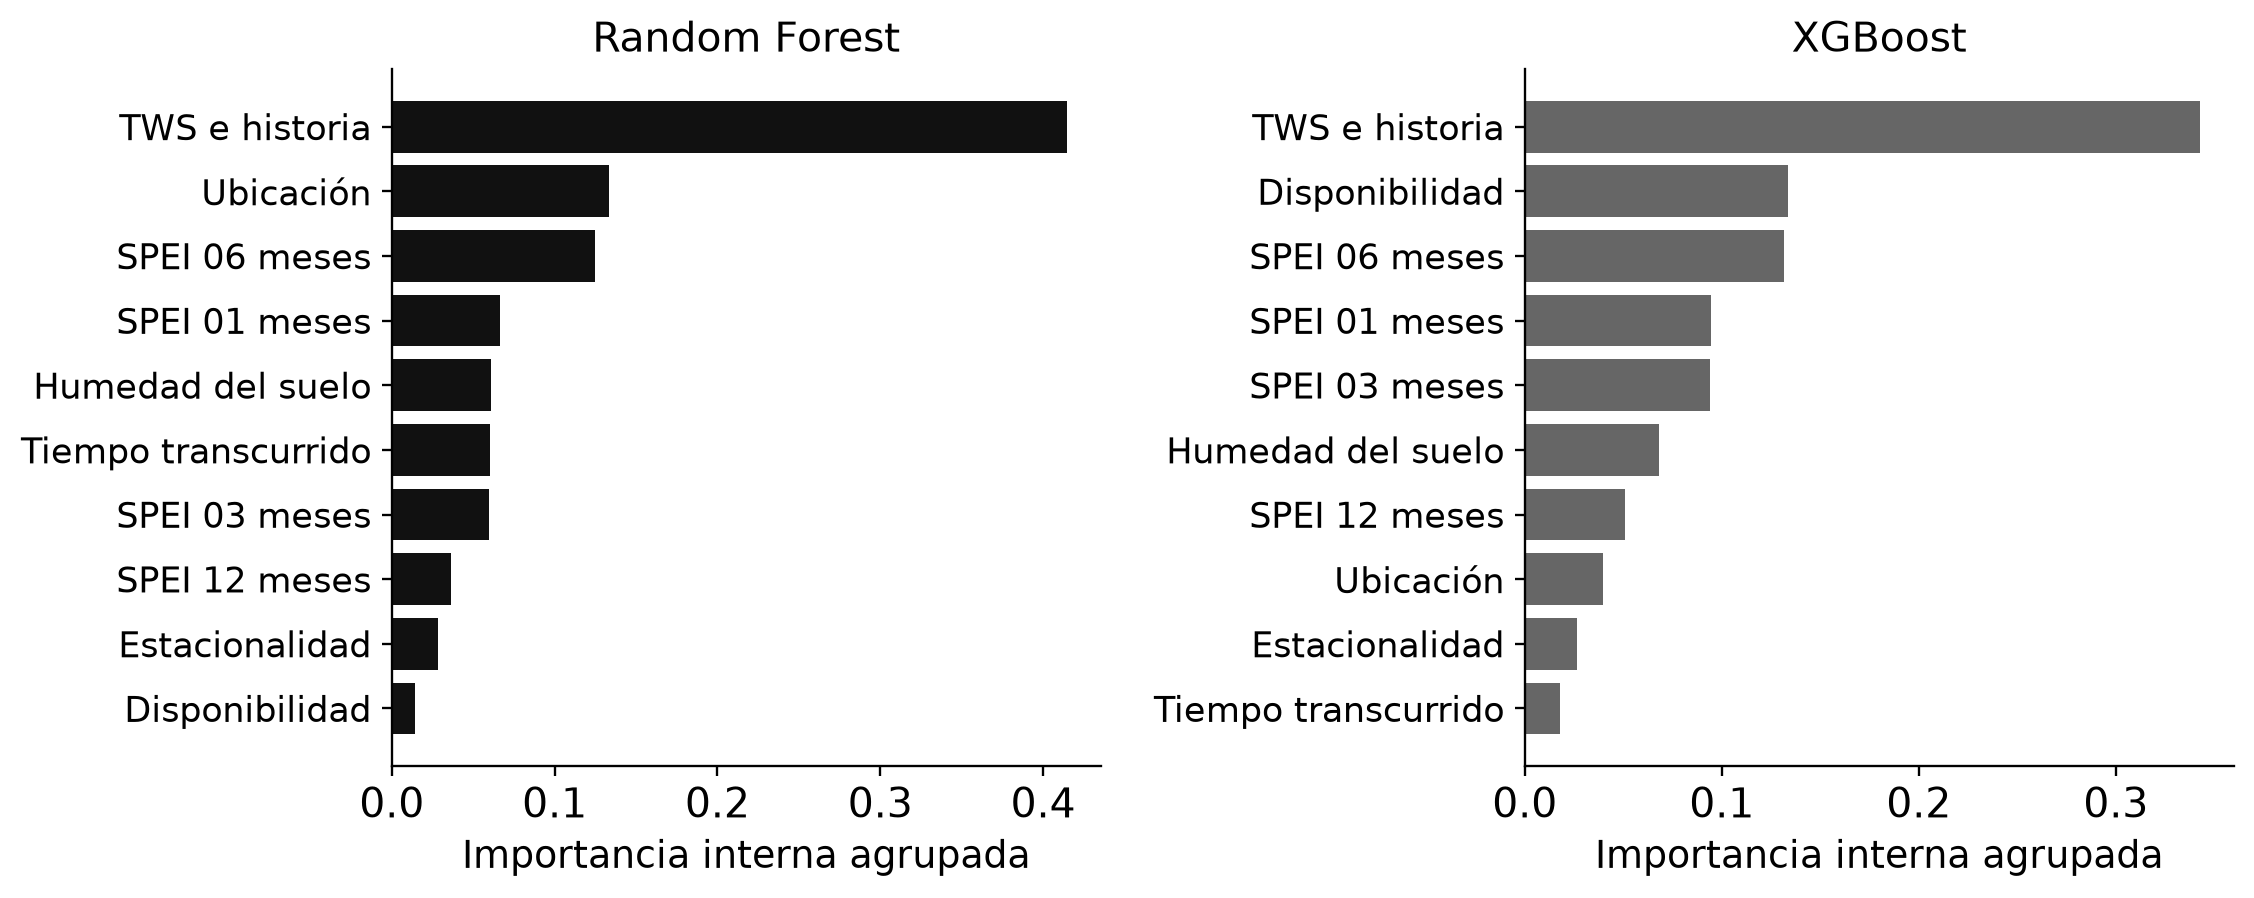

In [10]:
uncertainty=json.loads((RESULTS/'incertidumbre_bloques.json').read_text())
print('Meses observados:', uncertainty['observed_months'], 'Remuestreos:',uncertainty['repetitions'])
display(pd.DataFrame(uncertainty['intervals']))
display(pd.DataFrame(uncertainty['paired_differences']))
display(Image(filename=str(FIGURES/'12_importancias.png'), width=950))

## 10 Predicciones de Test y aplicación

Se reajustó cada configuración seleccionada con todas las etiquetas de Train.csv. Se entregan las columnas ID y Target para las 280 961 filas de Test. Estos archivos no permiten medir precisión sin sus etiquetas reales.

La aplicación se inicia con `python -m streamlit run app.py`. Permite explorar los datos, pronosticar una observación o un CSV y mostrar u ocultar métricas interactivas. El preprocesamiento es compartido con el entrenamiento.

In [11]:
rows=[]
for family in FAMILIES:
    frame=pd.read_csv(RESULTS/f'submission_{family}.csv')
    assert list(frame.columns)==['ID','Target']
    assert len(frame)==AUDIT['test_rows'] and frame.ID.is_unique
    assert np.isfinite(frame.Target).all()
    rows.append({'algoritmo':LABELS[family],'filas':len(frame),'mínimo_predicho':frame.Target.min(),'máximo_predicho':frame.Target.max()})
display(pd.DataFrame(rows))
print('No se calcula RMSE para Test porque no contiene etiquetas.')

,algoritmo,filas,mínimo_predicho,máximo_predicho
0,Random Forest,280961,-1.875957,1.993886
1,XGBoost,280961,-2.191243,2.855510
2,LSTM,280961,-2.434445,2.362993


No se calcula RMSE para Test porque no contiene etiquetas.


## 11 Conclusiones y reproducción

La comparación usa evaluación temporal y disponibilidad causal de entradas. La selección registrada en 2013 y el menor error final se presentan por separado. Los resultados no demuestran transferencia a regiones no observadas ni a todos los años futuros. Las versiones, semillas, huellas y parámetros quedan disponibles en los manifiestos.

In [12]:
display(Markdown(f"Modelo recomendado antes de abrir la prueba: **{LABELS[SUMMARY['recommended_family']]}**. Menor RMSE final descriptivo: **{LABELS[SUMMARY['best_holdout_family_descriptive']]}**."))
display(pd.DataFrame(SUMMARY['holdout_results'])[['algorithm','rmse','mae','r2','improvement_vs_persistence_pct']])
display(pd.DataFrame(json.loads((RESULTS/'entorno.json').read_text())['versions'].items(),columns=['paquete','versión']))

Modelo recomendado antes de abrir la prueba: **XGBoost**. Menor RMSE final descriptivo: **LSTM**.

,algorithm,rmse,mae,r2,improvement_vs_persistence_pct
0,Random Forest,0.716151,0.529016,0.283697,15.608265
1,XGBoost,0.703481,0.520752,0.308818,17.101295
2,LSTM,0.698856,0.518603,0.317875,17.646254


,paquete,versión
0,numpy,2.3.5
1,pandas,2.2.3
2,scipy,1.18.1
3,scikit-learn,1.9.1
4,xgboost,3.4.1
5,torch,2.14.1
6,streamlit,1.65.0
7,plotly,7.1.0
8,matplotlib,3.11.2
9,seaborn,0.13.2


## Referencias y materiales

La revisión bibliográfica completa y las citas APA se encuentran en `docs/Informe_Final_Parte2_TWS.md` y en el informe PDF/Word de `output/`. El código de entrenamiento se encuentra en `src/tws/training.py`, las arquitecturas en `src/tws/models.py` y `src/tws/neural.py`, y la preparación causal en `src/tws/data.py`.

Repositorio: https://github.com/Javiervalladares1/CC3084-Proyecto2-Drought-EDA

Reto: https://zindi.world/competitions/one-step-ahead-of-drought-forecasting-global-water-storage-challenge